In [1]:

import os
import time
import argparse
import cv2
import json
import numpy as np
from pycocotools import mask as cocomask
import multiprocessing as mp
import math

def db_eval_iou(annotation, segmentation, void_pixels=None):
    """ Compute region similarity as the Jaccard Index.
    Arguments:
        annotation   (ndarray): binary annotation   map.
        segmentation (ndarray): binary segmentation map.
        void_pixels  (ndarray): optional mask with void pixels

    Return:
        jaccard (float): region similarity
    """
    assert annotation.shape == segmentation.shape, \
        f'Annotation({annotation.shape}) and segmentation:{segmentation.shape} dimensions do not match.'
    annotation = annotation.astype(bool)
    segmentation = segmentation.astype(bool)

    if void_pixels is not None:
        assert annotation.shape == void_pixels.shape, \
            f'Annotation({annotation.shape}) and void pixels:{void_pixels.shape} dimensions do not match.'
        void_pixels = void_pixels.astype(bool)
    else:
        void_pixels = np.zeros_like(segmentation)

    # Intersection between all sets
    inters = np.sum((segmentation & annotation) & np.logical_not(void_pixels), axis=(0, 1))
    union = np.sum((segmentation | annotation) & np.logical_not(void_pixels), axis=(0, 1))
    # print(inters, union)
    union = np.where(union == 0, 1, union)
    
    j = inters / union
    if j.ndim == 0:
        j = 1 if np.isclose(union, 0) else j
    else:
        j[np.isclose(union, 0)] = 1
    return j


def db_eval_boundary(annotation, segmentation, void_pixels=None, bound_th=0.008):
    assert annotation.shape == segmentation.shape
    if void_pixels is not None:
        assert annotation.shape == void_pixels.shape
    if annotation.ndim == 3:
        n_frames = annotation.shape[0]
        f_res = np.zeros(n_frames)
        for frame_id in range(n_frames):
            void_pixels_frame = None if void_pixels is None else void_pixels[frame_id, :, :, ]
            f_res[frame_id] = f_measure(segmentation[frame_id, :, :, ], annotation[frame_id, :, :], void_pixels_frame, bound_th=bound_th)
    elif annotation.ndim == 2:
        f_res = f_measure(segmentation, annotation, void_pixels, bound_th=bound_th)
    else:
        raise ValueError(f'db_eval_boundary does not support tensors with {annotation.ndim} dimensions')
    return f_res


def f_measure(foreground_mask, gt_mask, void_pixels=None, bound_th=0.008):
    """
    Compute mean,recall and decay from per-frame evaluation.
    Calculates precision/recall for boundaries between foreground_mask and
    gt_mask using morphological operators to speed it up.

    Arguments:
        foreground_mask (ndarray): binary segmentation image.
        gt_mask         (ndarray): binary annotated image.
        void_pixels     (ndarray): optional mask with void pixels

    Returns:
        F (float): boundaries F-measure
    """
    assert np.atleast_3d(foreground_mask).shape[2] == 1
    if void_pixels is not None:
        void_pixels = void_pixels.astype(bool)
    else:
        void_pixels = np.zeros_like(foreground_mask).astype(bool)

    bound_pix = bound_th if bound_th >= 1 else \
        np.ceil(bound_th * np.linalg.norm(foreground_mask.shape))

    # Get the pixel boundaries of both masks
    fg_boundary = _seg2bmap(foreground_mask * np.logical_not(void_pixels))
    gt_boundary = _seg2bmap(gt_mask * np.logical_not(void_pixels))

    from skimage.morphology import disk

    # fg_dil = binary_dilation(fg_boundary, disk(bound_pix))
    fg_dil = cv2.dilate(fg_boundary.astype(np.uint8), disk(bound_pix).astype(np.uint8))
    # gt_dil = binary_dilation(gt_boundary, disk(bound_pix))
    gt_dil = cv2.dilate(gt_boundary.astype(np.uint8), disk(bound_pix).astype(np.uint8))

    # Get the intersection
    gt_match = gt_boundary * fg_dil
    fg_match = fg_boundary * gt_dil

    # Area of the intersection
    n_fg = np.sum(fg_boundary)
    n_gt = np.sum(gt_boundary)

    # % Compute precision and recall
    if n_fg == 0 and n_gt > 0:
        precision = 1
        recall = 0
    elif n_fg > 0 and n_gt == 0:
        precision = 0
        recall = 1
    elif n_fg == 0 and n_gt == 0:
        precision = 1
        recall = 1
    else:
        precision = np.sum(fg_match) / float(n_fg)
        recall = np.sum(gt_match) / float(n_gt)

    # Compute F measure
    if precision + recall == 0:
        F = 0
    else:
        F = 2 * precision * recall / (precision + recall)

    return F


def _seg2bmap(seg, width=None, height=None):
    """
    From a segmentation, compute a binary boundary map with 1 pixel wide
    boundaries.  The boundary pixels are offset by 1/2 pixel towards the
    origin from the actual segment boundary.
    Arguments:
        seg     : Segments labeled from 1..k.
        width	  :	Width of desired bmap  <= seg.shape[1]
        height  :	Height of desired bmap <= seg.shape[0]
    Returns:
        bmap (ndarray):	Binary boundary map.
     David Martin <dmartin@eecs.berkeley.edu>
     January 2003
    """

    seg = seg.astype(bool)
    seg[seg > 0] = 1

    assert np.atleast_3d(seg).shape[2] == 1

    width = seg.shape[1] if width is None else width
    height = seg.shape[0] if height is None else height

    h, w = seg.shape[:2]

    ar1 = float(width) / float(height)
    ar2 = float(w) / float(h)

    assert not (
        width > w | height > h | abs(ar1 - ar2) > 0.01
    ), "Can" "t convert %dx%d seg to %dx%d bmap." % (w, h, width, height)

    e = np.zeros_like(seg)
    s = np.zeros_like(seg)
    se = np.zeros_like(seg)

    e[:, :-1] = seg[:, 1:]
    s[:-1, :] = seg[1:, :]
    se[:-1, :-1] = seg[1:, 1:]

    b = seg ^ e | seg ^ s | seg ^ se
    b[-1, :] = seg[-1, :] ^ e[-1, :]
    b[:, -1] = seg[:, -1] ^ s[:, -1]
    b[-1, -1] = 0

    if w == width and h == height:
        bmap = b
    else:
        bmap = np.zeros((height, width))
        for x in range(w):
            for y in range(h):
                if b[y, x]:
                    j = 1 + math.floor((y - 1) + height / h)
                    i = 1 + math.floor((x - 1) + width / h)
                    bmap[j, i] = 1

    return bmap




In [2]:
import jsonlines
pred = []
with jsonlines.open('/mnt/petrelfs/yanziang/trackingllm/videoagent/logs/results/merge_new/seg/predictions11.jsonl', 'r') as f:
    for line in f:
        pred.append(line)

In [3]:
print(len(pred))
# pred = pred[534:]
# print(len(pred))
print(pred[0].keys())

90
dict_keys(['video', 'mask_path', 'pred'])


In [4]:
import json
with open('/mnt/petrelfs/yanziang/trackingllm/videoagent/davis17.json','r') as f:
    data = json.load(f)

data = data[:len(pred)]

In [5]:
import pycocotools.mask as mask_util
from petrel_client.client import Client
c = Client()


In [6]:
path = 'shdd:s3://refvos-youtube/Annotations_json/003234408d/1.json'
gt_masks = eval(c.get(path).decode())
gt_masks.keys()

dict_keys(['gt_mask'])

In [7]:
import multiprocessing

def eval_item(dd):
    try:
        path = dd['mask_path']
        gt_masks = eval(eval(c.get(path).decode())['gt_mask'])
        for mask in gt_masks:
            if mask is not None:
                none_mask = mask_util.decode(mask)
                # print(none_mask.shape)
                none_mask = np.zeros_like(none_mask)
                none_mask = mask_util.encode(none_mask)
                # print(none_mask)
                break
        gt_masks_replace = []
        for mask in gt_masks:
            if mask is None:
                gt_masks_replace.append(none_mask)
            else:
                gt_masks_replace.append(mask)
        f = db_eval_iou(mask_util.decode(eval(dd['pred']))>0, (mask_util.decode(gt_masks_replace)>0))
        v = db_eval_boundary(mask_util.decode(eval(dd['pred']))>0, (mask_util.decode(gt_masks_replace)>0))
        f = np.mean(f)
        v = np.mean(v)
        print({'f':f, 'v':v})
    except Exception as e:
        # print(e)
        return {'f':0, 'v':0} 
        
    return {'f':f, 'v':v}

# 输入参数列表
inputs = list(pred)

with multiprocessing.Pool(processes=64) as pool:
    results = pool.map(eval_item, inputs)

# print(f"返回值: {results}")


{'f': 0.9601174424577826, 'v': 0.9938884288358734}
{'f': 0.9286163185765156, 'v': 0.9889376700101956}
{'f': 0.9493192053180518, 'v': 0.9921198446686309}
{'f': 0.5256948450757777, 'v': 0.41460322841295466}
{'f': 0.8215849435788191, 'v': 0.908734019474031}
{'f': 0.0801383355469915, 'v': 0.5026352824972246}
{'f': 0.8586667564312698, 'v': 0.9725923747028297}
{'f': 0.8965902478393711, 'v': 0.9903702035961366}
{'f': 0.42647615106522246, 'v': 0.8539047881816685}
{'f': 0.8129269404311905, 'v': 0.9934616171954204}
{'f': 0.8765583254007979, 'v': 0.9835421758516034}
{'f': 0.840838548493134, 'v': 0.9039812437135666}
{'f': 0.9611363989143331, 'v': 0.9903858897887386}
{'f': 0.9338113423755359, 'v': 0.9231732038758634}
{'f': 0.6445671918021917, 'v': 0.6834041371222406}
{'f': 0.7414244938193623, 'v': 0.9808538944667166}
{'f': 0.7443293271199601, 'v': 0.859256349586343}
{'f': 0.9140707063682018, 'v': 0.9534405168474749}
{'f': 0.7998570834157094, 'v': 0.9780435012266196}
{'f': 0.6917999647844565, 'v': 0

In [14]:
all_f = []
all_v = []
for dd in results:
    # if dd['f'] > 0.1:
    all_f.append(dd['f'])
    all_v.append(dd['v'])
print(len(all_f), len(all_v))
vs = np.array(all_v)
fs = np.array(all_f)
fin_v = np.mean(vs)
fin_f = np.mean(fs)
fin_v, fin_f
# (0.527378513249987, 0.17841627454264689)
# (0.530809590851342, 0.1828174428047219)
# (0.4577423125854374, 0.1372897143547346)
# (0.5931668439865144, 0.2402039474335558)
# (0.7040379373958313, 0.37446300394382004)

90 90


(0.7818869718292055, 0.613452809201777)

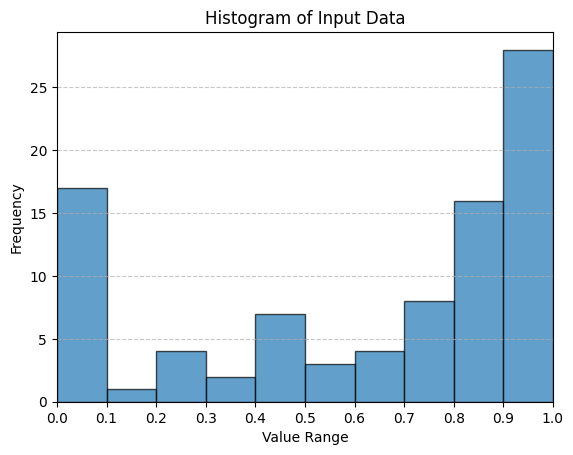

In [12]:
import numpy as np
import matplotlib.pyplot as plt

def plot_histogram(data):
    # 确保输入是一个一维的numpy.ndarray
    if not isinstance(data, np.ndarray) or data.ndim != 1:
        raise ValueError("Input must be a one-dimensional numpy.ndarray.")
    
    # 确保数据在0到1的范围内
    if not np.all((data >= 0) & (data <= 1)):
        raise ValueError("All values in the input array must be in the range [0, 1].")
    
    # 设置阈值区间
    bins = np.arange(0, 1.1, 0.1)  # 创建区间 [0, 0.1, 0.2, ..., 1.0]
    
    # 绘制直方图
    plt.hist(data, bins=bins, edgecolor='black', alpha=0.7)
    plt.title('Histogram of Input Data')
    plt.xlabel('Value Range')
    plt.ylabel('Frequency')
    plt.xticks(bins)
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.xlim(0, 1)
    plt.show()

plot_histogram(fs)